# 14. 사람 단위 3-fold 교차검증 2단계: 전처리 재검증(CV2)

1단계(12번 노트북)에서 개선형으로 분류된 stretch·aspect384·ccrop과 기준 letterbox를 seed 43·44로 더 돌렸습니다. seed 42는 1단계 결과를 그대로 씁니다. 후보마다 3 fold × 3 seed = 9쌍입니다.

- 조건: Full FT. 전처리와 seed만 바꿉니다. 실행 ID는 `CV2-<이름>-s<seed>-f<fold>`(seed 42는 `CV1-<이름>-f<fold>`)입니다.
- **짝 비교**: Δ_{s,f} = F1(후보, seed s, fold f) − F1(letterbox, seed s, fold f). Δ̄_f는 fold f에서 세 seed의 Δ 평균입니다.
- **채택 기준(실행 전 `experiments/CV/PLAN.md`)**

| 판정 | 조건 |
|---|---|
| 채택(성능 개선) | 9쌍 평균 Δ ≥ +0.010, 9쌍 중 6쌍 이상 Δ > 0, Δ̄_f > 0인 fold 2개 이상, 붕괴 경향 없음 |
| 채택(효율 대안) | 9쌍 평균 Δ ≥ −0.005, epoch당 학습 시간 ≤ 기준의 0.7배 |
| 채택 안 함 | 그 밖 |

- **붕괴 경향(2단계 실행 전 정의)**: fold마다 세 seed의 클래스별 Recall 평균을 구하고, 어떤 클래스든 그 값이 0.20 미만인 fold가 2개 이상이면 붕괴 경향입니다.
- fold 9쌍은 독립 표본이 아닙니다(fold끼리 학습 데이터가 겹치고, 같은 fold의 seed는 같은 사람을 검증). 통계적 유의성은 주장하지 않습니다.
- fold 점수는 Early Stopping과 같은 데이터로 매긴 것이라 낙관적입니다. 후보 사이 비교용입니다.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, class_names, set_korean_font

print("font:", set_korean_font())
pd.set_option("display.width", 220)
NAMES = class_names()
EXP = ROOT / "experiments"
PRE = {"letterbox": ("letterbox", 224), "stretch": ("stretch", 224), "aspect384": ("aspect", 384), "ccrop": ("ccrop", 224)}
SEEDS, FOLDS = (42, 43, 44), (1, 2, 3)

def run_dir(name, s, f):
    return EXP / (f"CV1-{name}-f{f}" if s == 42 else f"CV2-{name}-s{s}-f{f}") / "full"

rows = []
for name, (pre, size) in PRE.items():
    for s in SEEDS:
        for f in FOLDS:
            dd = run_dir(name, s, f)
            sm = json.loads((dd / "summary.json").read_text(encoding="utf-8")); cf = json.loads((dd / "config.json").read_text(encoding="utf-8"))
            assert (cf["cv_fold"], cf["preprocess"], cf["input_size"], cf["seed"]) == (f, pre, size, s), dd
            h = pd.read_csv(dd / "history.csv")
            rec = sm["val"]["per_class"]["recall"]
            rows.append({"전처리": name, "seed": s, "fold": f, "Macro F1": sm["val"]["macro_f1"],
                         "최저 Recall": min(rec.values()), "최저 클래스": min(rec, key=rec.get), **{f"R:{k}": v for k, v in rec.items()},
                         "best/last": f"{sm['best_epoch']}/{sm['epochs_run']}", "Best−Last F1": sm["val"]["macro_f1"] - h.val_macro_f1.iloc[-1],
                         "epoch당(초)": sm["mean_train_epoch_s"], "전체(분)": sm["total_time_s"] / 60})
cv = pd.DataFrame(rows)
print(len(cv), "runs")
cv.pivot_table(index=["전처리", "seed"], columns="fold", values="Macro F1").round(4)

font: Malgun Gothic
36 runs


fold                 1       2       3
전처리       seed                        
aspect384 42    0.8652  0.8939  0.8688
          43    0.8569  0.8814  0.8762
          44    0.8831  0.8874  0.8504
ccrop     42    0.9009  0.8759  0.8649
          43    0.8694  0.8775  0.8525
          44    0.8743  0.8785  0.8642
letterbox 42    0.8193  0.8730  0.8423
          43    0.8443  0.8609  0.8206
          44    0.8347  0.8793  0.8338
stretch   42    0.8282  0.8840  0.8755
          43    0.8474  0.8655  0.8627
          44    0.8536  0.8638  0.8568

## 1. 9쌍 짝 비교와 판정

In [2]:
key = ["seed", "fold"]
base = cv[cv["전처리"] == "letterbox"].set_index(key)
rcols = [c for c in cv.columns if c.startswith("R:")]
out, deltas = [], {}
for name in [n for n in PRE if n != "letterbox"]:
    g = cv[cv["전처리"] == name].set_index(key)
    d = (g["Macro F1"] - base["Macro F1"])
    deltas[name] = d
    dbar = d.groupby(level="fold").mean()
    # 붕괴: fold마다 seed 평균 Recall → 최저 클래스가 0.20 미만인 fold 수
    fr = g[rcols].groupby(level="fold").mean()
    low = fr.min(axis=1)
    coll = int((low < 0.20).sum())
    t_ratio = g["epoch당(초)"].mean() / base["epoch당(초)"].mean()
    m, pos, fpos = d.mean(), int((d > 0).sum()), int((dbar > 0).sum())
    perf = (m >= 0.010) and (pos >= 6) and (fpos >= 2) and (coll < 2)
    eff = (m >= -0.005) and (t_ratio <= 0.7)
    verdict = "채택(성능 개선)" if perf else ("채택(효율 대안)" if eff else "채택 안 함")
    out.append({"전처리": name, "9쌍 평균 Δ": m, "Δ>0 쌍": f"{pos}/9", "Δ̄ f1": dbar[1], "Δ̄ f2": dbar[2], "Δ̄ f3": dbar[3],
                "Δ̄_f>0 fold": fpos, "Δ 최소": d.min(), "Δ 최대": d.max(),
                "붕괴 fold": coll, "붕괴 클래스(fold별)": ", ".join(f"f{f}:{fr.loc[f].idxmin()[2:]} {low[f]:.2f}" for f in FOLDS if low[f] < 0.20) or "-",
                "시간 비율": t_ratio, "판정": verdict})
res = pd.DataFrame(out).set_index("전처리")
res.round(4)

,9쌍 평균 Δ,Δ>0 쌍,Δ̄ f1,Δ̄ f2,Δ̄ f3,Δ̄_f>0 fold,Δ 최소,Δ 최대,붕괴 fold,붕괴 클래스(fold별),시간 비율,판정
전처리,,,,,,,,,,,,
stretch,0.0144,8/9,0.0103,0.0000,0.0328,3,-0.0154,0.0421,0,-,0.9829,채택(성능 개선)
aspect384,0.0283,9/9,0.0356,0.0165,0.0329,3,0.0082,0.0556,1,f3:바벨 로우 0.11,1.4331,채택(성능 개선)
ccrop,0.0278,8/9,0.0488,0.0062,0.0283,3,-0.0007,0.0817,2,"f2:바벨 로우 0.14, f3:바벨 로우 0.04",1.0179,채택 안 함


In [3]:
pd.DataFrame({n: d.unstack("fold").round(4).stack() for n, d in deltas.items()}).unstack().round(4)

stretch                 aspect384                   ccrop                
fold       1       2       3         1       2       3       1       2       3
seed                                                                          
42    0.0089  0.0110  0.0331    0.0460  0.0209  0.0264  0.0817  0.0028  0.0225
43    0.0030  0.0046  0.0421    0.0126  0.0204  0.0556  0.0251  0.0166  0.0318
44    0.0189 -0.0154  0.0230    0.0484  0.0082  0.0165  0.0396 -0.0007  0.0304

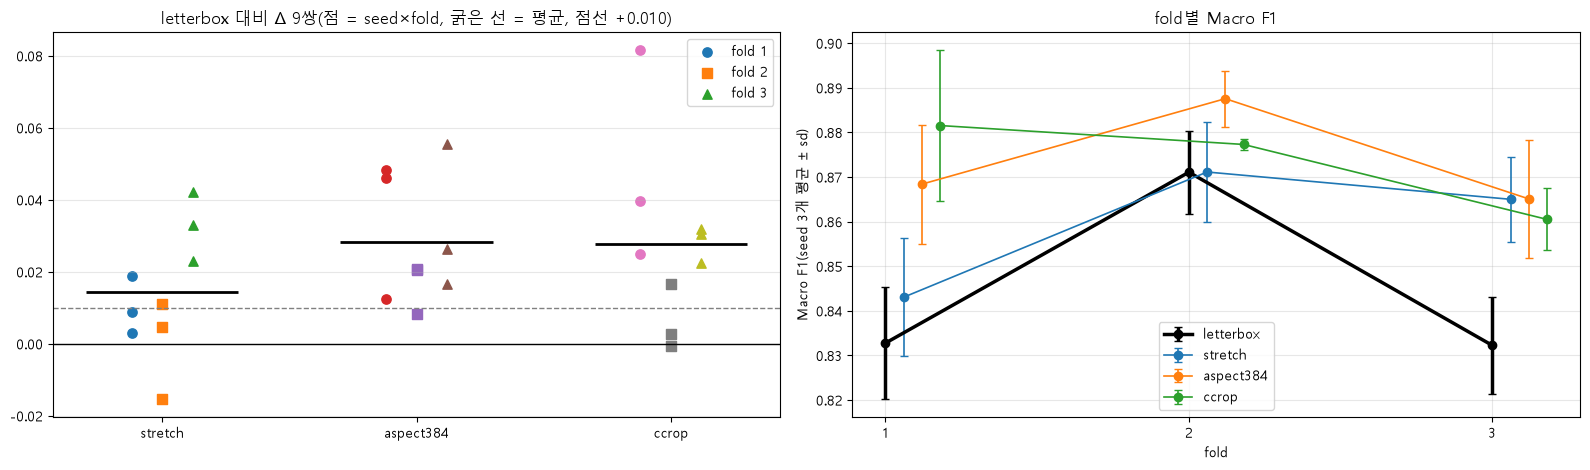

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
names = list(deltas)
for i, n in enumerate(names):
    d = deltas[n].reset_index()
    for f, mk in zip(FOLDS, "os^"):
        dd = d[d["fold"] == f]
        axes[0].scatter(np.full(len(dd), i) + (f - 2) * 0.12, dd["Macro F1"], marker=mk, s=45, label=f"fold {f}" if i == 0 else None)
    axes[0].hlines(res.loc[n, "9쌍 평균 Δ"], i - 0.3, i + 0.3, color="k", lw=2)
axes[0].axhline(0, color="k", lw=1); axes[0].axhline(0.01, color="gray", ls="--", lw=1)
axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels(names); axes[0].legend(); axes[0].grid(alpha=.3, axis="y")
axes[0].set_title("letterbox 대비 Δ 9쌍(점 = seed×fold, 굵은 선 = 평균, 점선 +0.010)")
for n in PRE:
    g = cv[cv["전처리"] == n].groupby("fold")["Macro F1"]
    axes[1].errorbar(np.array(FOLDS) + list(PRE).index(n) * 0.06, g.mean(), yerr=g.std(ddof=1), marker="o", capsize=3,
                     lw=2.5 if n == "letterbox" else 1.2, color="k" if n == "letterbox" else None, label=n)
axes[1].set_xticks(FOLDS); axes[1].set_xlabel("fold"); axes[1].set_ylabel("Macro F1(seed 3개 평균 ± sd)"); axes[1].legend(); axes[1].grid(alpha=.3)
axes[1].set_title("fold별 Macro F1")
plt.tight_layout(); plt.savefig(FIGURES / "cv2_preprocessing.png", dpi=110); plt.show()

## 2. seed 흔들림과 1단계(seed 42) 대비

In [5]:
sd = cv.groupby(["전처리", "fold"])["Macro F1"].std(ddof=1).unstack().round(4)
sd["fold 평균 sd"] = sd.mean(axis=1).round(4)
s42 = {n: deltas[n].xs(42, level="seed").mean() for n in deltas}
pd.concat([sd, pd.DataFrame({"1단계 평균 Δ(seed 42)": s42, "2단계 9쌍 평균 Δ": res["9쌍 평균 Δ"]}).round(4)], axis=1)

,1,2,3,fold 평균 sd,1단계 평균 Δ(seed 42),2단계 9쌍 평균 Δ
aspect384,0.0134,0.0063,0.0133,0.0110,0.0311,0.0283
ccrop,0.0170,0.0013,0.0070,0.0084,0.0357,0.0278
letterbox,0.0126,0.0093,0.0109,0.0109,NaN,NaN
stretch,0.0132,0.0112,0.0095,0.0113,0.0177,0.0144


## 3. 클래스별 Recall(9회 평균 ± sd)와 Early Stopping 낙관

In [6]:
order = [c for g in GROUPS.values() for c in g]
tab = {}
for n in PRE:
    g = cv[cv["전처리"] == n]
    tab[n] = [f"{g[f'R:{NAMES[c]}'].mean():.2f}±{g[f'R:{NAMES[c]}'].std(ddof=1):.2f}" for c in order]
pd.DataFrame(tab, index=[f"{c} {NAMES[c]}" for c in order])

,letterbox,stretch,aspect384,ccrop
0 Y - Exercise,0.95±0.04,0.95±0.05,0.96±0.04,0.96±0.06
1 니푸쉬업,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00
4 라잉 레그 레이즈,0.88±0.11,0.85±0.10,0.89±0.09,0.92±0.09
10 바이시클 크런치,0.82±0.11,0.81±0.06,0.85±0.06,0.84±0.08
2 덤벨 벤트오버 로우,0.67±0.17,0.75±0.11,0.81±0.09,0.83±0.05
7 바벨 데드리프트,0.68±0.16,0.73±0.13,0.80±0.07,0.85±0.06
8 바벨 런지,0.98±0.02,0.98±0.01,0.98±0.01,0.98±0.01
9 바벨 로우,0.27±0.13,0.30±0.11,0.25±0.14,0.17±0.13
3 딥스,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00
5 랫풀 다운,0.99±0.00,0.99±0.01,0.99±0.01,0.99±0.02


In [7]:
fold_low = {n: cv[cv["전처리"] == n].groupby("fold")["R:바벨 로우"].mean().round(3) for n in PRE}
bl = pd.DataFrame(fold_low).T
bl.columns = [f"바벨 로우 f{f}" for f in FOLDS]
bl["Best−Last 평균"] = cv.groupby("전처리")["Best−Last F1"].mean().reindex(bl.index).round(4)
bl["Best−Last 최대"] = cv.groupby("전처리")["Best−Last F1"].max().reindex(bl.index).round(4)
bl["epoch당(초)"] = cv.groupby("전처리")["epoch당(초)"].mean().reindex(bl.index).round(1)
bl["전체(분) 평균"] = cv.groupby("전처리")["전체(분)"].mean().reindex(bl.index).round(1)
bl

,바벨 로우 f1,바벨 로우 f2,바벨 로우 f3,Best−Last 평균,Best−Last 최대,epoch당(초),전체(분) 평균
letterbox,0.269,0.352,0.198,0.0209,0.0719,8.5,3.0
stretch,0.250,0.352,0.284,0.0129,0.0403,8.4,3.2
aspect384,0.358,0.281,0.112,0.0105,0.0194,12.2,3.4
ccrop,0.314,0.143,0.044,0.0245,0.0748,8.7,2.7


## 4. 해석(2026-11-26, 2단계 24회 + 1단계 seed 42)

### 판정(실행 전 기준 그대로)
| 전처리 | 9쌍 평균 Δ | Δ>0 쌍 | Δ̄_f>0 fold | 붕괴 fold | epoch 시간 비율 | 판정 |
|---|---|---|---|---|---|---|
| aspect384 | +0.028 | 9/9 | 3 | 1 | 1.43 | **채택(성능 개선)** |
| stretch | +0.014 | 8/9 | 3 | 0 | 0.98 | **채택(성능 개선)** |
| ccrop | +0.028 | 8/9 | 3 | 2 | 1.02 | **채택 안 함(붕괴 경향)** |

- **aspect384**: 9쌍이 모두 올랐고 가장 작은 Δ도 +0.008입니다. 세 후보 중 가장 안정적입니다. 대신 epoch 시간이 1.43배이고, fold 3에서 바벨 로우 Recall이 0.11로 낮습니다(붕괴 fold 1개라 기준에는 걸리지 않음).
- **stretch**: 평균 +0.014로 기준(+0.010)을 넘었습니다. 다만 fold 2의 Δ̄는 +0.00005로 사실상 0입니다(+0.011, +0.005, −0.015). 확실한 개선은 fold 1·3에서만 보였습니다. 비용은 기준과 같습니다.
- **ccrop**: 평균 Δ는 aspect384와 같지만, 바벨 로우가 fold 2·3에서 0.14·0.04로 무너졌습니다. 1단계의 붕괴 경향이 seed를 바꿔도 그대로 남았습니다. 규칙대로 채택하지 않습니다.

### 1단계 판정이 seed를 바꿔도 유지됐습니다
- 1단계(seed 42)의 평균 Δ와 2단계 9쌍 평균 Δ가 가깝습니다(aspect384 0.031→0.028, ccrop 0.036→0.028, stretch 0.018→0.014). seed 42가 조금 운 좋은 쪽이었지만 방향은 같습니다.
- 같은 조건에서 seed만 바꾼 흔들림(fold별 sd)은 0.008~0.011입니다. 공식 Val의 seed sd 0.014보다 작습니다. 검증 사람이 많아져 판정이 덜 흔들린 것으로 보입니다.
- 그래도 stretch의 fold 2처럼 한 seed가 −0.015를 낼 수 있습니다. seed 한 번만으로 판정하지 않고 2단계를 둔 이유입니다.

### 오류는 사라지지 않고 바벨 로우로 모입니다
- 사람이 크게 보이게 하는 전처리(ccrop, aspect384)는 덤벨 로우(0.67→0.83·0.81)와 데드리프트(0.68→0.85·0.80)를 크게 올렸습니다. 같은 묶음의 바벨 로우는 그대로이거나 더 떨어졌습니다(0.27→0.17·0.25).
- 바벨 로우 정답 이미지(9회 합계 1,128장)가 어디로 갔는지 혼동행렬로 세었습니다. 가장 많이 간 곳은 **데드리프트**이고, 사람을 크게 보는 전처리일수록 늘었습니다(letterbox 493 → stretch 541 → aspect384 626 → ccrop 683장). 덤벨 로우로 간 수는 오히려 줄었습니다(259 → 182~207).
- 세 운동은 모두 상체를 숙이고 바벨·덤벨을 잡는 자세입니다. 모델이 사람을 더 자세히 볼수록 덤벨 로우와 데드리프트는 더 잘 구분하지만, 바벨 로우는 데드리프트 쪽으로 더 자주 끌려갑니다. 바벨 로우는 "데드리프트보다 더 숙이고, 바벨을 배꼽 쪽으로 당기는" 중간 자세라 사진 한 장으로 경계를 긋기 어렵습니다(H1에서도 클립 평균으로 풀리지 않음).
- 기준 letterbox도 fold 3에서 바벨 로우가 0.198로 0.20 아래입니다. 바벨 로우는 전처리의 문제라기보다 **과제 자체의 약점**입니다.

### Early Stopping 낙관
- Best−Last 평균은 0.011~0.025입니다. ccrop(0.025)과 기준(0.021)이 크고 aspect384(0.011)가 가장 작습니다. aspect384는 최고 시점과 마지막 시점의 차이가 가장 작았습니다. 어느 후보도 낙관 정도가 판정을 뒤집을 만큼 다르지는 않습니다.

### 의미와 한계
- **채택은 "사람 단위 CV에서 letterbox보다 낫다"는 뜻입니다.** E08 Test는 동결했으므로, 새 전처리로 다시 학습한 모델의 Test 점수는 내지 않습니다. 보고서에는 E08(letterbox) 결과를 공식 결과로 두고, CV 결과는 "이후 실험에서 찾은 개선 방향"으로 나눠 적습니다.
- 두 후보가 함께 채택됐을 때 하나를 고르는 규칙은 미리 정하지 않았습니다. 결과를 본 뒤 규칙을 만들지 않고, 장단점(aspect384: 더 크고 안정적, 1.43배 비용 / stretch: 작지만 비용 같음)을 함께 보고합니다.
- fold 9쌍은 독립 표본이 아니고, 점수는 Early Stopping과 같은 데이터에서 나와 낙관적입니다. 통계적 유의성은 주장하지 않습니다.